# Chapter 8 · Project: the rain twin on real links (OpenMRG, Gothenburg)
**Level: Expert** · ~30 min · 2D · *Applied project, part 2 of 2*

Chapter 7 showed on simulated rain that a link-driven twin maps about as well as IDW and
**forecasts much better**, because its state carries the storm's motion. Now the real thing:

* **OpenMRG** (SMHI, July 2015): 364 links over Gothenburg, rain rates per link from the
  dataset's reference retrieval `R`, averaged to 5 minutes
* **SMHI radar**: 2 km, 5-minute rain rates; we use its grid for the twin
* **10 municipal rain gauges**, which the twin **never sees**. They are the independent check.

Data are read from the OpenSense example subset that FieldSense downloads
(`~/data/cml/openmrg/_sample_8d`, or set `OPENMRG_DIR`).

**Questions**
1. *Estimation:* at the gauges, is the twin's map better than IDW of the links, and than the radar?
2. *Prediction:* can the twin forecast what the links will read 5–60 minutes ahead better than
   persistence?
3. *Physics check:* does the motion the twin learns from the links agree with the motion seen
   by the radar?

In [1]:
import sys, time; sys.path.insert(0, "..")
import warnings; warnings.filterwarnings("ignore", category=RuntimeWarning)
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML
from dtwin import viz
from raintwin import RainTwin, line_idw, path_operator
from raintwin.openmrg import OpenMRG
viz.set_style()

d = OpenMRG()
L = d.links
X, Y = np.meshgrid(d.x, d.y)
H_gauge = path_operator(d.gauges["x"], d.gauges["y"], d.gauges["x"], d.gauges["y"], d.x, d.y)
print(f"grid {d.y.size} x {d.x.size} cells of {d.x[1]-d.x[0]:.0f} km;  {L['xa'].size} links;  "
      f"{d.gauges['x'].size} gauges")

grid 45 x 36 cells of 2 km;  364 links;  10 gauges


## 1. The network

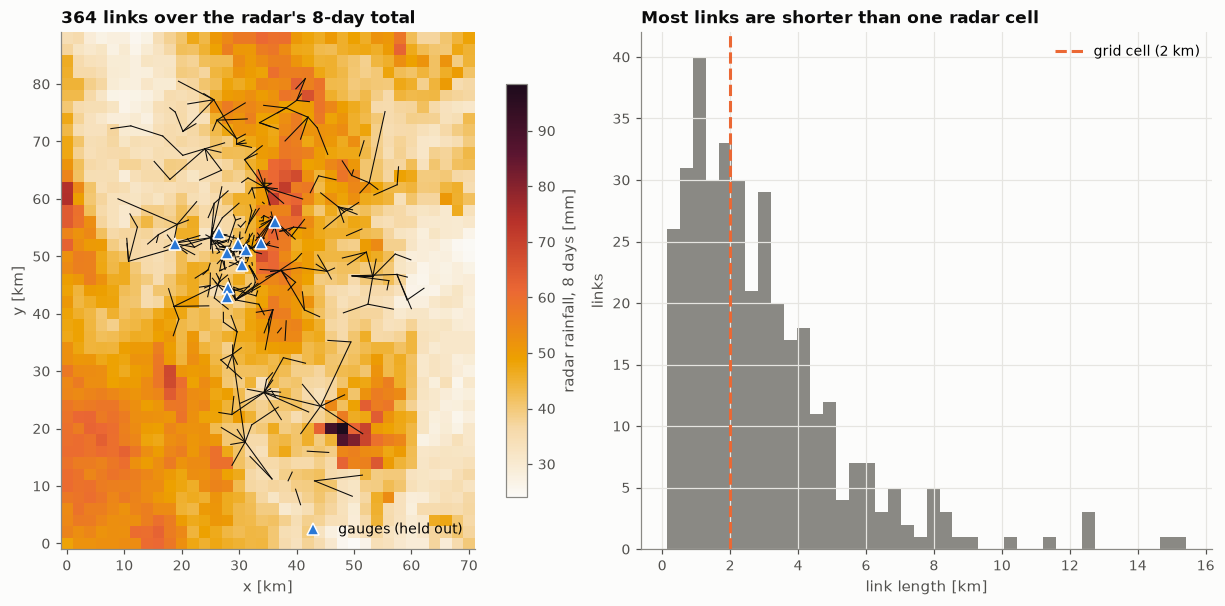

In [2]:
EVENTS = [("2015-07-25 04:00", "2015-07-25 11:00"), ("2015-07-26 00:00", "2015-07-26 07:00"),
          ("2015-07-28 13:00", "2015-07-28 19:00"), ("2015-07-29 00:00", "2015-07-29 10:00")]
rad_total, _ = d.radar("2015-07-22", "2015-07-29 23:55")
fig, axes = plt.subplots(1, 2, figsize=(12, 5.4), constrained_layout=True)
ax = axes[0]
ax.grid(False)
im = ax.imshow(np.nansum(rad_total, 0) / 12, origin="lower", cmap=viz.FIELD,
               extent=(d.x[0] - 1, d.x[-1] + 1, d.y[0] - 1, d.y[-1] + 1))
plt.colorbar(im, ax=ax, label="radar rainfall, 8 days [mm]", shrink=0.8)
for i in range(L["xa"].size):
    ax.plot([L["xa"][i], L["xb"][i]], [L["ya"][i], L["yb"][i]], color=viz.INK, lw=0.7)
ax.plot(d.gauges["x"], d.gauges["y"], "^", color=viz.BLUE, ms=8, mec="white", label="gauges (held out)")
ax.set(xlabel="x [km]", ylabel="y [km]", title="364 links over the radar's 8-day total")
ax.legend(loc="lower right")
ax = axes[1]
lens = np.hypot(L["xb"] - L["xa"], L["yb"] - L["ya"])
ax.hist(lens, bins=40, color=viz.MUTED)
ax.axvline(2.0, color=viz.ORANGE, ls="--", label="grid cell (2 km)")
ax.set(xlabel="link length [km]", ylabel="links", title="Most links are shorter than one radar cell")
ax.legend()
viz.save(fig, "08_openmrg_network.png")
plt.show()

The network is dense in the city and thin outside. Most links are shorter than a 2 km cell, so
several links share one cell and often disagree with each other. Keep that in mind: it limits
how closely *any* gridded map can fit the links.

## 2. A first look: do links and radar agree?

In [3]:
s0, e0 = EVENTS[0]
y0, _ = d.link_rain(s0, e0)
rad0, _ = d.radar(s0, e0)
H_link = path_operator(L["xa"], L["ya"], L["xb"], L["yb"], d.x, d.y)
rad_on_links = np.array([H_link @ np.nan_to_num(f).ravel() for f in rad0])
ok = np.isfinite(y0)
print(f"radar along links vs link rain, 5-min, event 1: corr {np.corrcoef(rad_on_links[ok], y0[ok])[0,1]:.2f}; "
      f"mean radar {rad_on_links[ok].mean():.2f} vs links {y0[ok].mean():.2f} mm/h")

radar along links vs link rain, 5-min, event 1: corr 0.27; mean radar 1.00 vs links 0.69 mm/h


Weak agreement, and the radar reads higher than the links. That matches FieldSense's finding that
Gothenburg's radar is the weakest of its three networks. **So the radar is not truth here.**
We judge the twin at the gauges, and treat the radar as one more competitor.

## 3. Running the twin on four storms
Same twin as Chapter 7 (40 members, log-rain state, velocity in the state, 15 km localization).
Starting from almost nothing (a flat field and a velocity prior of 0 ± 20 km/h), it must learn
everything from the links. Every 15 minutes it also issues a 1-hour forecast.

In [4]:
def run_event(start, end, fc_every=3, seed=1):
    y, times = d.link_rain(start, end)
    g, _ = d.gauge_rain(start, end)
    rad, _ = d.radar(start, end)
    T = min(len(y), len(g), len(rad))
    tw = RainTwin(d.x, d.y, L, seed=seed)
    tw.initialise(np.full(X.shape, max(np.nanmean(y[0]), 0.1)), background=0.3, vel_std=20)
    out = {k: [] for k in ("twin_g", "idw_g", "radar_g", "gauge", "V", "fit", "mean", "spread", "idw")}
    out["fc"] = []
    for k in range(T):
        if k:
            tw.forecast(5 / 60)
        st = tw.analysis(y[k])
        idw = line_idw(y[k], L["xa"], L["ya"], L["xb"], L["yb"], X, Y)
        out["twin_g"].append(H_gauge @ tw.mean.ravel()); out["idw_g"].append(H_gauge @ idw.ravel())
        out["radar_g"].append(H_gauge @ np.nan_to_num(rad[k]).ravel()); out["gauge"].append(g[k])
        out["V"].append(tw.V.mean(0)); out["fit"].append(st.get("fit_corr", np.nan))
        out["mean"].append(tw.mean); out["spread"].append(tw.spread); out["idw"].append(idw)
        if k >= 6 and k % fc_every == 0 and k + 12 < T:
            P, _ = tw.predict(12, 5 / 60)
            out["fc"].append((k, np.array([tw.H @ p.ravel() for p in P]),
                              np.array([H_gauge @ p.ravel() for p in P])))
    for key in out:
        if key != "fc":
            out[key] = np.array(out[key])
    out.update(y=y[:T], g=g[:T], rad=rad[:T], times=times[:T], T=T)
    return out

results = {}
for s, e in EVENTS:
    t0 = time.time()
    results[s[:10]] = run_event(s, e)
    r = results[s[:10]]
    print(f"{s[:16]}: {r['T']} cycles in {time.time()-t0:.0f}s, final velocity {r['V'][-1].round(1)} km/h")

2015-07-25 04:00: 85 cycles in 4s, final velocity [ 3.  10.4] km/h


2015-07-26 00:00: 85 cycles in 4s, final velocity [13.  11.9] km/h


2015-07-28 13:00: 73 cycles in 3s, final velocity [-2.1 15.8] km/h


2015-07-29 00:00: 121 cycles in 5s, final velocity [ 8.6 21.9] km/h


## 4. Estimation: the map, judged at the gauges

In [5]:
def corr(a, b):
    a, b = np.ravel(a), np.ravel(b)
    ok = np.isfinite(a) & np.isfinite(b)
    return np.corrcoef(a[ok], b[ok])[0, 1]

def rmse(a, b):
    a, b = np.ravel(a), np.ravel(b)
    ok = np.isfinite(a) & np.isfinite(b)
    return np.sqrt(np.mean((a[ok] - b[ok]) ** 2))

rows = []
print(f"{'event':12s} {'corr: twin':>11s} {'IDW':>6s} {'radar':>6s}   {'RMSE: twin':>11s} {'IDW':>6s} {'radar':>6s}")
for ev, r in results.items():
    sl = slice(6, None)                                   # skip the 30-minute spin-up
    c = [corr(r[k][sl], r["gauge"][sl]) for k in ("twin_g", "idw_g", "radar_g")]
    e = [rmse(r[k][sl], r["gauge"][sl]) for k in ("twin_g", "idw_g", "radar_g")]
    rows.append(c + e)
    print(f"{ev:12s} {c[0]:11.2f} {c[1]:6.2f} {c[2]:6.2f}   {e[0]:11.2f} {e[1]:6.2f} {e[2]:6.2f}")
rows = np.array(rows)
print(f"{'mean':12s} {rows[:,0].mean():11.2f} {rows[:,1].mean():6.2f} {rows[:,2].mean():6.2f}   "
      f"{rows[:,3].mean():11.2f} {rows[:,4].mean():6.2f} {rows[:,5].mean():6.2f}")

event         corr: twin    IDW  radar    RMSE: twin    IDW  radar
2015-07-25          0.62   0.60   0.47          0.81   0.88   1.23
2015-07-26          0.73   0.77   0.45          3.54   3.12   4.19
2015-07-28          0.40   0.72   0.25          6.61   5.16   6.74
2015-07-29          0.60   0.65   0.50          3.00   2.71   3.57
mean                0.59   0.69   0.42          3.49   2.97   3.93


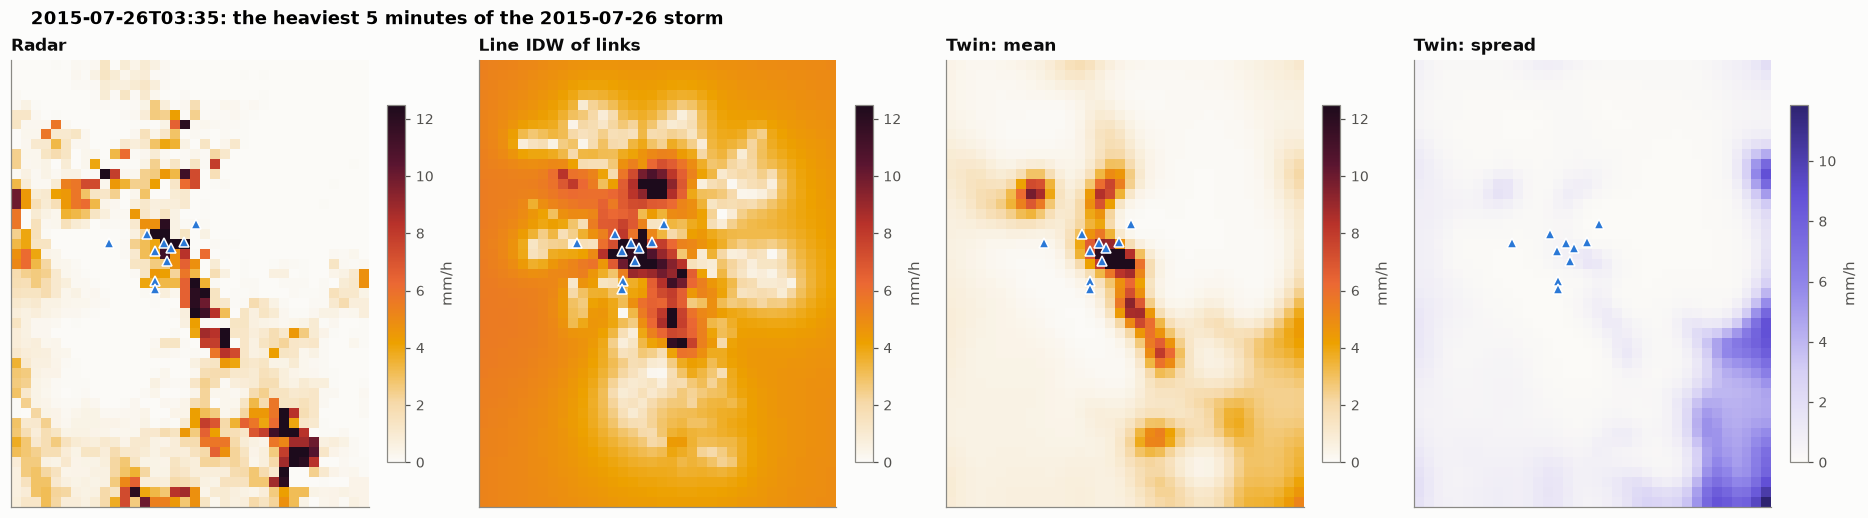

In [6]:
ev = "2015-07-26"
r = results[ev]
k = int(np.argmax(np.nanmean(r["y"], 1)))
vm = np.nanpercentile(r["idw"][k], 99)
fig, axes = plt.subplots(1, 4, figsize=(17, 4.6), constrained_layout=True)
for ax, (F, ttl, cm, hi) in zip(axes, [(r["rad"][k], "Radar", viz.FIELD, vm),
                                       (r["idw"][k], "Line IDW of links", viz.FIELD, vm),
                                       (r["mean"][k], "Twin: mean", viz.FIELD, vm),
                                       (r["spread"][k], "Twin: spread", viz.UNCERTAINTY, None)]):
    ax.grid(False)
    im = ax.imshow(F, origin="lower", cmap=cm, vmin=0, vmax=hi,
                   extent=(d.x[0] - 1, d.x[-1] + 1, d.y[0] - 1, d.y[-1] + 1))
    ax.plot(d.gauges["x"], d.gauges["y"], "^", color=viz.BLUE, ms=6, mec="white")
    plt.colorbar(im, ax=ax, shrink=0.8, label="mm/h")
    ax.set(title=ttl, xticks=[], yticks=[])
fig.suptitle(f"{str(r['times'][k])[:16]}: the heaviest 5 minutes of the {ev} storm", x=0.02, ha="left",
             fontweight="bold")
viz.save(fig, "08_openmrg_maps.png")
plt.show()

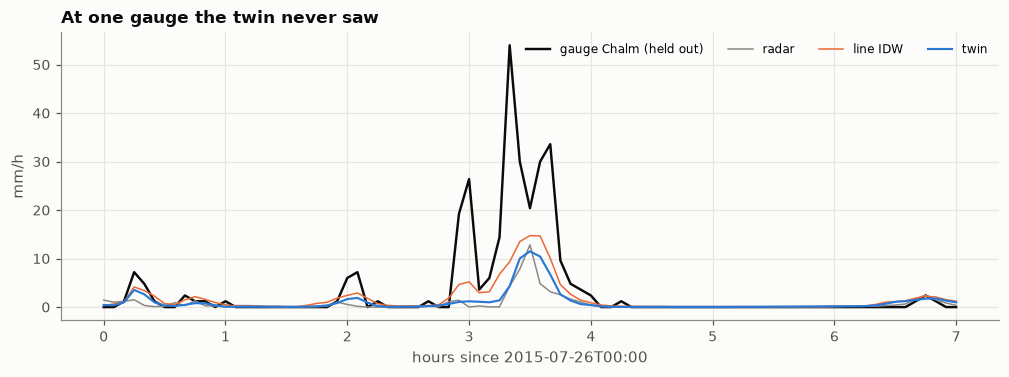

In [7]:
gi = int(np.nanargmax(np.nansum(r["gauge"], 0)))
tt = (r["times"] - r["times"][0]) / np.timedelta64(1, "h")
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(tt, r["gauge"][:, gi], color=viz.TRUTH, lw=1.6, label=f"gauge {d.gauges['id'][gi]} (held out)")
ax.plot(tt, r["radar_g"][:, gi], color=viz.MUTED, lw=1, label="radar")
ax.plot(tt, r["idw_g"][:, gi], color=viz.ORANGE, lw=1, label="line IDW")
ax.plot(tt, r["twin_g"][:, gi], color=viz.TWIN, lw=1.4, label="twin")
ax.set(xlabel=f"hours since {str(r['times'][0])[:16]}", ylabel="mm/h", title="At one gauge the twin never saw")
ax.legend(ncol=4, fontsize=8)
plt.show()

**Reading the estimation result.** The twin beats the radar at the gauges in every storm.
Against IDW of the links it wins the steady stratiform storm (25 July) and loses the others,
most clearly the convective 28 July storm. Two reasons, both visible above:
* IDW reproduces each link's value exactly near that link, and the gauges sit inside the dense
  city network, so near-link accuracy is what gets scored.
* The twin's 2 km grid and 40-member ensemble smooth the field. The twin fits the links only to
  correlation 0.4–0.7 (printed as `fit` below), because many short links share one cell and
  disagree.

In [8]:
for ev, r in results.items():
    print(f"{ev}: twin's fit to the links it assimilates, mean corr {np.nanmean(r['fit'][6:]):.2f}")

2015-07-25: twin's fit to the links it assimilates, mean corr 0.36
2015-07-26: twin's fit to the links it assimilates, mean corr 0.74
2015-07-28: twin's fit to the links it assimilates, mean corr 0.67
2015-07-29: twin's fit to the links it assimilates, mean corr 0.66


## 5. Prediction: what will the links read next?
For every forecast we compare the twin's predicted link readings at 5–60 minutes with what the
links actually read later. The baseline is **persistence**: each link keeps its current value.
This test needs no radar and no gauge: the network checks itself.

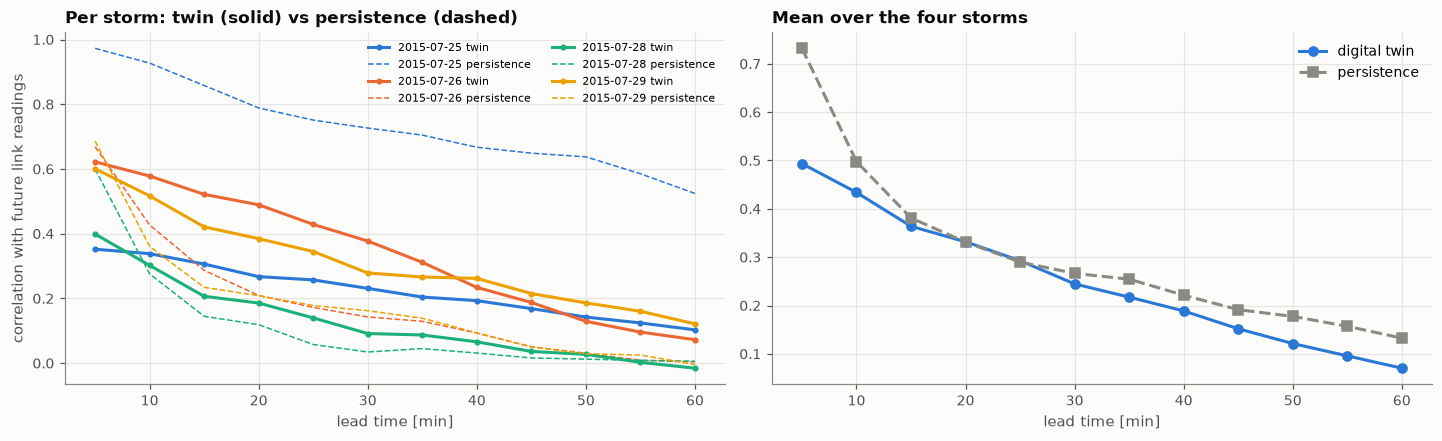

  5 min: twin 0.49   persistence 0.73
 15 min: twin 0.36   persistence 0.38
 30 min: twin 0.24   persistence 0.27
 60 min: twin 0.07   persistence 0.13


In [9]:
hz = np.arange(1, 13)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.9), constrained_layout=True)
all_tw, all_ps = [], []
for j, (ev, r) in enumerate(results.items()):
    ctw, cps = [], []
    for h in hz:
        a = np.concatenate([P_l[h - 1] for k, P_l, _ in r["fc"]])
        p = np.concatenate([r["y"][k] for k, _, _ in r["fc"]])
        o = np.concatenate([r["y"][k + h] for k, _, _ in r["fc"]])
        ctw.append(corr(a, o)); cps.append(corr(p, o))
    all_tw.append(ctw); all_ps.append(cps)
    axes[0].plot(hz * 5, ctw, "o-", color=viz.SERIES[j], ms=3, label=f"{ev} twin")
    axes[0].plot(hz * 5, cps, "--", color=viz.SERIES[j], lw=1, label=f"{ev} persistence")
axes[0].set(xlabel="lead time [min]", ylabel="correlation with future link readings",
            title="Per storm: twin (solid) vs persistence (dashed)")
axes[0].legend(fontsize=7, ncol=2)
mt, mp = np.mean(all_tw, 0), np.mean(all_ps, 0)
axes[1].plot(hz * 5, mt, "o-", color=viz.TWIN, label="digital twin")
axes[1].plot(hz * 5, mp, "s--", color=viz.MUTED, label="persistence")
axes[1].set(xlabel="lead time [min]", title="Mean over the four storms")
axes[1].legend()
viz.save(fig, "08_openmrg_nowcast.png")
plt.show()
for h in (1, 3, 6, 12):
    print(f"{h*5:3d} min: twin {mt[h-1]:.2f}   persistence {mp[h-1]:.2f}")

**Reading the prediction result.** At 5 minutes persistence wins clearly: the links' own last
value is hard to beat, and the twin's smoothed map loses some of each link's detail. At 15–30
minutes the twin wins in three of the four storms, because rain has moved and the twin moved it
too. **Averaged over all four it is only a tie**, because 25 July is a slow, steady storm where
persistence stays excellent for an hour. At 60 minutes neither method has much skill. A twin
should learn to recognise the slow regime (a direction listed below).

## 6. Physics check: does the learned motion match the radar?
The twin learned the storm velocity **from the links only**. Here is an independent estimate from
the radar: the shift that best aligns consecutive radar frames (phase correlation, accumulated
over each storm).

2015-07-25: twin (links only) [0.6 9.3] km/h   radar phase correlation [0. 0.] km/h
2015-07-26: twin (links only) [ 6.  14.1] km/h   radar phase correlation [ 0. 32.] km/h
2015-07-28: twin (links only) [-5.4 11.2] km/h   radar phase correlation [ 0. 16.] km/h
2015-07-29: twin (links only) [ 8.1 18.5] km/h   radar phase correlation [ 8. 16.] km/h


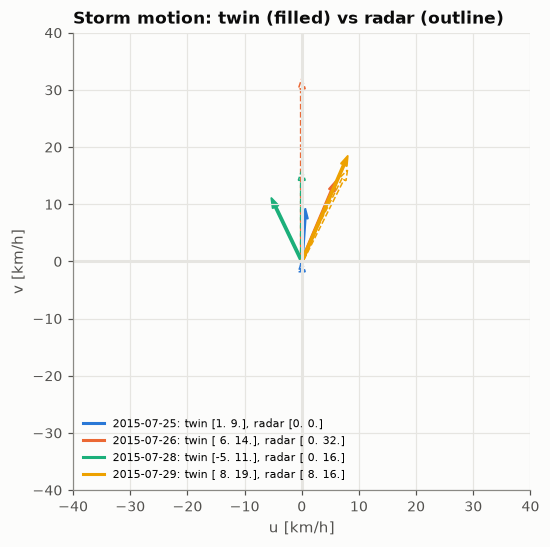

In [10]:
def radar_motion(rad, dx_km=2.0, lag=3, dt_h=5 / 60):
    """Mean motion from phase correlation of radar frames `lag` steps apart (15 min by default)."""
    F = np.nan_to_num(rad)
    F = F - F.mean((1, 2), keepdims=True)
    acc = 0
    for a, b in zip(F[:-lag], F[lag:]):
        A, B = np.fft.fft2(a), np.fft.fft2(b)
        acc = acc + B * np.conj(A)
    cc = np.real(np.fft.ifft2(acc / (np.abs(acc) + 1e-9)))
    iy, ix = np.unravel_index(np.argmax(cc), cc.shape)
    ny, nx = cc.shape
    sy = iy if iy <= ny // 2 else iy - ny
    sx = ix if ix <= nx // 2 else ix - nx
    return np.array([sx, sy]) * dx_km / (lag * dt_h)

fig, ax = plt.subplots(figsize=(6, 5.4))
for j, (ev, r) in enumerate(results.items()):
    vr = radar_motion(r["rad"])
    vt = r["V"][len(r["V"]) // 2:].mean(0)
    ax.arrow(0, 0, *vt, color=viz.SERIES[j], width=0.4, length_includes_head=True)
    ax.arrow(0, 0, *vr, color=viz.SERIES[j], width=0.4, ls="--", fill=False, length_includes_head=True)
    ax.plot([], [], color=viz.SERIES[j], label=f"{ev}: twin {vt.round(0)}, radar {vr.round(0)}")
    print(f"{ev}: twin (links only) {vt.round(1)} km/h   radar phase correlation {vr.round(1)} km/h")
ax.axhline(0, color=viz.GRID); ax.axvline(0, color=viz.GRID)
ax.set(xlim=(-40, 40), ylim=(-40, 40), aspect="equal", xlabel="u [km/h]", ylabel="v [km/h]",
       title="Storm motion: twin (filled) vs radar (outline)")
ax.legend(fontsize=7, loc="lower left")
plt.show()

The radar estimate is coarse: whole 2 km cells per 15 minutes, so steps of 8 km/h. Read it as a
direction-and-size check. In these July storms both estimates point mainly **north**, at
similar speeds. The twin learned that motion from the links alone, which a link map cannot do.

## Conclusions
| Question | Answer on OpenMRG |
|---|---|
| Map vs radar at gauges | twin better in every storm |
| Map vs IDW at gauges | IDW better in 3 of 4 storms: inside a dense network, near-link accuracy wins |
| 5-min forecast | persistence better |
| 15–30-min forecast | twin better in 3 of 4 storms; a tie on average (persistence excels in the slow storm) |
| 60-min forecast | little skill for either |
| Motion from links alone | learned, and checkable against radar |

**What to build on this (a product view):** use IDW, or FieldSense's RNN retrieval, for the
*now* map inside the network, and the **twin for the forecast and for the uncertainty map**.
Even better, feed the twin the better retrieval as its observations.

**Research directions**
1. **Sub-grid links:** use a 500 m twin grid in the city (or aggregate co-located links) so the
   twin can fit the links as closely as IDW.
2. **Regime awareness:** persistence wins in slow stratiform rain. Estimate the growth/decay rate
   and the background as parameters too, like κ in Chapter 3.
3. **More sensors:** gauges and PWS as point observations (same `path_operator`), and radar as an
   observation with its own bias parameter.
4. **New York:** OpenMesh links and PWS through `pcpn_maps` retrieval, scored against MRMS and
   ASOS over its 52 storms.